In [ ]:
#1.Importing Library Functions

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
from datetime import datetime

import warnings


In [ ]:
#2.Reading the file 

In [2]:
df=pd.read_csv('googleplaystore.csv')
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
df.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [5]:
#3. Checking shape,columns and datatype

In [6]:
df.shape

(10841, 13)

In [7]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


In [9]:
df.dtypes

App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

In [10]:
#3.1. Checking missing values

In [11]:
df.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [12]:
#3.2. Find duplicate rows

In [13]:
df.duplicated().sum()

np.int64(483)

In [ ]:
#4. Remove rows where “Rating” is missing.

In [14]:
df=df.dropna(subset='Rating')
df

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10834,FR Calculator,FAMILY,4.0,7,2.6M,500+,Free,0,Everyone,Education,"June 18, 2017",1.0.0,4.1 and up
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device


In [ ]:
#5.Fill missing values in “Type” with the most frequent value. 

In [15]:
df['Type'].mode()[0]

'Free'

In [16]:
df['Type']=df['Type'].fillna(df['Type'].mode()[0])
print(df)

                                                     App             Category  \
0         Photo Editor & Candy Camera & Grid & ScrapBook       ART_AND_DESIGN   
1                                    Coloring book moana       ART_AND_DESIGN   
2      U Launcher Lite – FREE Live Cool Themes, Hide ...       ART_AND_DESIGN   
3                                  Sketch - Draw & Paint       ART_AND_DESIGN   
4                  Pixel Draw - Number Art Coloring Book       ART_AND_DESIGN   
...                                                  ...                  ...   
10834                                      FR Calculator               FAMILY   
10836                                   Sya9a Maroc - FR               FAMILY   
10837                   Fr. Mike Schmitz Audio Teachings               FAMILY   
10839                      The SCP Foundation DB fr nn5n  BOOKS_AND_REFERENCE   
10840      iHoroscope - 2018 Daily Horoscope & Astrology            LIFESTYLE   

       Rating Reviews      

In [17]:
#6. Remove duplicates records from the dataset


In [18]:
df.drop_duplicates()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10834,FR Calculator,FAMILY,4.0,7,2.6M,500+,Free,0,Everyone,Education,"June 18, 2017",1.0.0,4.1 and up
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device


In [ ]:
#7.Drop rows where Content Rating, Current Ver, or Android Ver are null

In [19]:
cols_to_clean = ['Content Rating', 'Current Ver', 'Android Ver']
df = df.dropna(subset=cols_to_clean)

In [20]:
df.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

In [21]:
#8.Clean and Convert Numerical Columns

In [22]:
df['Reviews'] = df['Reviews'].astype(int)
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(int)
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)

In [23]:
print(df['Reviews'].dtype)

int64


In [24]:
print(df['Installs'].dtype)

int64


In [25]:
print(df['Price'].dtype)

float64


In [26]:
#8.1. Clean and Standardize App

In [27]:
def clean_size(size):
    if 'M' in size:
        return float(size.replace('M', ''))
    elif 'k' in size:
        return float(size.replace('k', '')) / 1024
    else:
        return np.nan

df['Size'] = df['Size'].apply(clean_size)

In [28]:
#8.2. Get a Summary

In [29]:
df.describe()

,Rating,Reviews,Size,Installs,Price
count,9360.000000,9.360000e+03,7723.000000,9.360000e+03,9360.000000
mean,4.191838,5.143767e+05,22.970120,1.790875e+07,0.961279
std,0.515263,3.145023e+06,23.449949,9.126637e+07,15.821640
min,1.000000,1.000000e+00,0.008301,1.000000e+00,0.000000
25%,4.000000,1.867500e+02,5.300000,1.000000e+04,0.000000
50%,4.300000,5.955000e+03,14.000000,5.000000e+05,0.000000
75%,4.500000,8.162750e+04,33.000000,5.000000e+06,0.000000
max,5.000000,7.815831e+07,100.000000,1.000000e+09,400.000000


In [30]:
#Visualization

In [ ]:
#9. Line Plot- App Rating Trend Over the Years

In [31]:
#Convert 'Last Updated' to datetime and extract the Year
df['Year'] = pd.to_datetime(df['Last Updated']).dt.year

In [32]:
#Calculate average rating per year
yearly_ratings = df.groupby('Year')['Rating'].mean().reset_index()

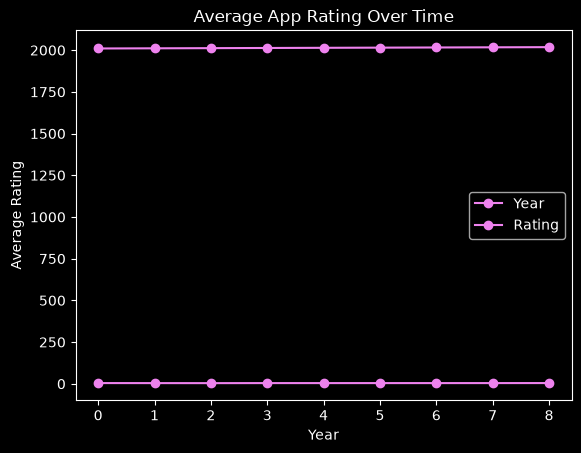

In [38]:
#Create the Line Plot
plt.style.use("dark_background")
yearly_ratings.plot(marker='o',color='Violet')

plt.title("Average App Rating Over Time")
plt.xlabel("Year")
plt.ylabel("Average Rating")

plt.show()

In [ ]:
#10.Bar chart- Top 10 App Categories by Total Installs (Horizontal Bar Chart)

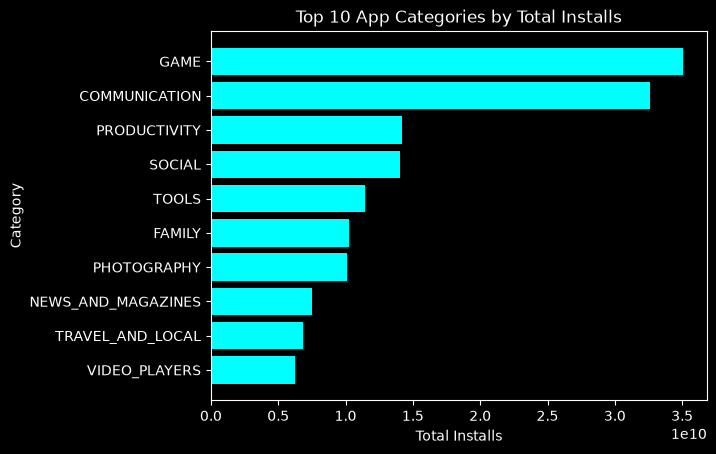

In [39]:
plt.style.use("dark_background")

#Aggregate data
top_categories = df.groupby("Category")["Installs"].sum().sort_values().tail(10)

#Plot using plt.barh()
plt.barh(top_categories.index, top_categories.values, color="cyan")

plt.title("Top 10 App Categories by Total Installs")
plt.xlabel("Total Installs")
plt.ylabel("Category")
plt.show()

In [ ]:
#11.Bar Chart- Free vs. Paid Apps Count (Vertical Bar Chart)

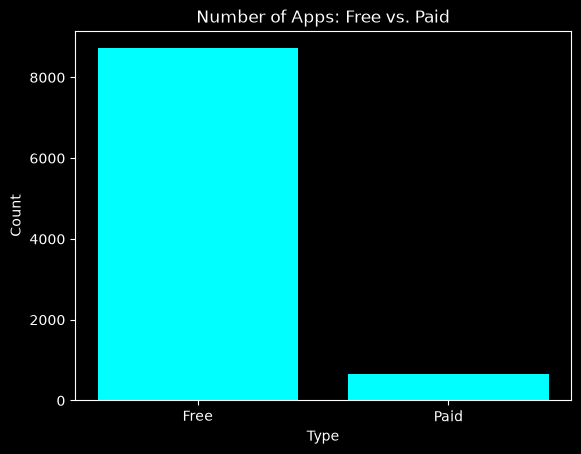

In [40]:
plt.style.use("dark_background")

#Aggregate data
type_counts = df["Type"].value_counts()

#Plot using plt.bar()
plt.bar(type_counts.index, type_counts.values, color="cyan")

plt.title("Number of Apps: Free vs. Paid")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

In [ ]:
#12.Pie Chart- Free vs. Paid Apps

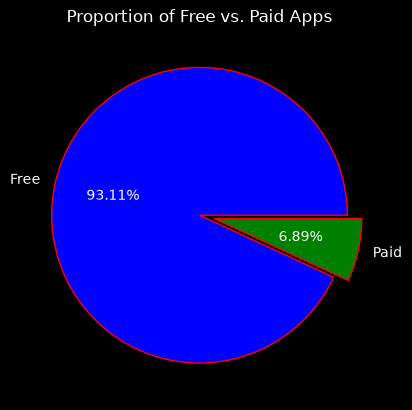

In [41]:
plt.style.use("dark_background")

#Aggregate data
type_counts = df["Type"].value_counts()

#Plot using plt.pie()
custom_colors = ["blue", "green"]

plt.pie(type_counts.values, labels=type_counts.index, autopct="%1.2f%%",wedgeprops={'edgecolor':'red'},explode=[0, 0.1],colors=custom_colors)

plt.title("Proportion of Free vs. Paid Apps")
plt.show()

In [ ]:
#13.Scatter plot- Reviews vs. Installs

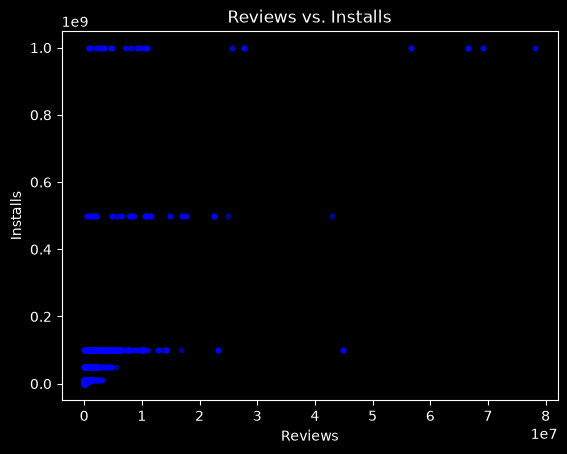

In [44]:
plt.style.use("dark_background")

# Plot Reviews on X-axis vs Installs on Y-axis
plt.scatter(df["Reviews"], df["Installs"], color="blue", s=10, alpha=0.5)

plt.title("Reviews vs. Installs")
plt.xlabel("Reviews")
plt.ylabel("Installs")
plt.show()

In [45]:
#14.Histogram- Rating Distribution

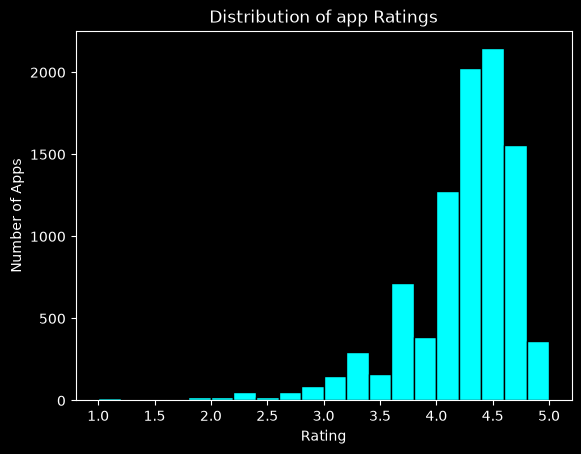

In [48]:
plt.style.use("dark_background")

#Create a histogram of app ratings"
plt.hist(df["Rating"],bins=20, color="cyan", edgecolor="black")

plt.title("Distribution of app Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.show()

In [49]:
#15.Histogram- Free vs. Paid App Sizes

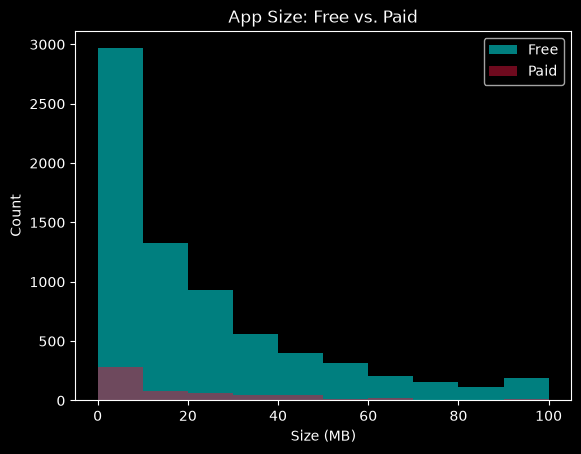

In [50]:
plt.style.use("dark_background")

# 1. Filter sizes
free = df[df["Type"] == "Free"]["Size"]
paid = df[df["Type"] == "Paid"]["Size"]

# 2. Plot
plt.hist(free, color="cyan", alpha=0.5, label="Free")
plt.hist(paid, color="crimson", alpha=0.5, label="Paid")

plt.title("App Size: Free vs. Paid")
plt.xlabel("Size (MB)")
plt.ylabel("Count")
plt.legend()
plt.show()